# Análisis de Tests de Perlin Noise

Este notebook combina los tests de uniformidad, avalancha y patrones para el generador de hashes usado en el ruido Perlin.
> **ADVERTENCIA:** La ejecución de estos tests es un proceso intensivo que requiere de un tiempo considerable. Como referencia, en un procesador Ryzen 7 5700X utilizando todos los hilos, la ejecución tomó más de 2 horas.

In [29]:
import re
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
import numpy as np
from PIL import Image
from scipy.stats import chi2, binom

In [30]:
FIGSIZE            = (16, 7.5)
TITLE_FONT_SIZE    = 24
SUBTITLE_FONT_SIZE = 20
LEGEND_FONT_SIZE   = 18
LABEL_FONT_SIZE    = 16
TICK_FONT_SIZE     = 16

COLOR_BLUE         = '#1B4182'
COLOR_LIGHT_GREEN  = '#90BE6D'
COLOR_GREEN        = "#2FAE53"
COLOR_YELLOW       = '#F9C74F'
COLOR_ORANGE       = '#F9844A'
COLOR_RED          = '#C0392B'

GRAY_DARK          = '#6E6E6E'
GRAY               = '#C0C0C0'
GRAY_LIGHT         = '#D0D0D0'
GRAY_LIGHTER       = '#E0E0E0'


plt.rc('font',   size=LABEL_FONT_SIZE)
plt.rc('axes',   titlesize=TITLE_FONT_SIZE, labelsize=LABEL_FONT_SIZE)
plt.rc('xtick',  labelsize=TICK_FONT_SIZE)
plt.rc('ytick',  labelsize=TICK_FONT_SIZE)
plt.rc('legend', fontsize=LEGEND_FONT_SIZE)
plt.rc('figure', titlesize=TITLE_FONT_SIZE)

## 1. Test de Uniformidad

Analiza si la distribución de valores generados por el hash es uniforme.

### 1.1 Extracción de Datos

Compilación y ejecución del test C para obtención de métricas (frecuencias, entropía, Chi-cuadrado).

In [31]:
uniformity_output_file = Path("results/uniformity_output_64b.txt")
uniformity_output_file.parent.mkdir(parents=True, exist_ok=True)

UNIFORMITY_SAMPLES = 10_000_000_000
LOG_START_INDEX = 100
LOG_FACTOR = 10 ** (1/100)
SEED = 123456789

print("Compilando uniformity_test...")
subprocess.run(["make", "compile_uniformity_64b"], check=True)

print("\nEjecutando test...")
cmd = ["./bin/uniformity_64b", str(UNIFORMITY_SAMPLES), str(LOG_START_INDEX), str(LOG_FACTOR), str(SEED)]
print(' '.join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True, check=True)
data_uniformity = result.stdout
uniformity_output_file.write_text(data_uniformity)

Compilando uniformity_test...
mkdir -p ./bin
gcc -fopenmp -Wall -std=c23 -march=native -mbmi2 -avx2 -Ofast -o ./bin/uniformity_64b common.c tests/test_uniformity_64b.c -lm -lpng


gcc: error: unrecognized command-line option ‘-avx2’; did you mean ‘-mavx2’?
make: *** [Makefile:16: compile_uniformity_64b] Error 1


CalledProcessError: Command '['make', 'compile_uniformity_64b']' returned non-zero exit status 2.

#### 1.1.1 Datos en bruto obtenidos

In [ ]:
data_uniformity.strip().splitlines()[:5]

['{000000000000100, 65436.00, 65436.00, 65436.00, 65436.00, 6.64385619}',
 '{000000000000102, 65434.00, 65434.00, 65434.00, 65434.00, 6.67242534}',
 '{000000000000104, 65432.00, 65432.00, 65432.00, 65432.00, 6.70043972}',
 '{000000000000106, 65430.00, 65430.00, 65430.00, 65430.00, 6.72792045}',
 '{000000000000108, 65428.00, 65428.00, 65428.00, 65428.00, 6.75488750}']

In [ ]:
data_uniformity.strip().splitlines()[-32:-27]

['{000006426133309, 65367.66, 65255.81, 65891.68, 66092.96, 15.99999263}',
 '{000006575817182, 65384.36, 65208.35, 65974.87, 66074.09, 15.99999280}',
 '{000006728987640, 65316.04, 65112.05, 65999.72, 66095.51, 15.99999296}',
 '{000006885725897, 65313.01, 65058.37, 66020.69, 66067.46, 15.99999313}',
 '{000007046115057, 65414.23, 65108.00, 65933.36, 66054.19, 15.99999328}']

### 1.2 Refinado de Datos

Procesamiento de salida textual a estructuras numéricas ($f_{abs}$, $\chi^2$, $H$).

In [ ]:
frequencies_regex = re.compile(r'(\d+): (\d+)')
frequency_matches = frequencies_regex.findall(data_uniformity)

# Formato: {Total, Chi2_W0, Chi2_W1, Chi2_W2, Chi2_W3, AvgEntropy}
metrics_log_regex = re.compile(r'\{(\d+), ([\d.]+), ([\d.]+), ([\d.]+), ([\d.]+), ([\d.]+)\}')
metrics_matches = metrics_log_regex.findall(data_uniformity)

f_abs = [int(value) for _, value in frequency_matches]

chi2_log = [(int(idx), [float(c0), float(c1), float(c2), float(c3)]) 
            for idx, c0, c1, c2, c3, _ in metrics_matches]

entropy_log = [(int(idx), float(ent)) for idx, _, _, _, _, ent in metrics_matches]

### 1.3 Visualización de Datos

#### 1.3.1 Convergencia del Test Chi-Cuadrado ($\chi^2$)

Evolución de $\chi^2$ respecto al número de muestras $N$. Bandas de confianza para distribución uniforme.

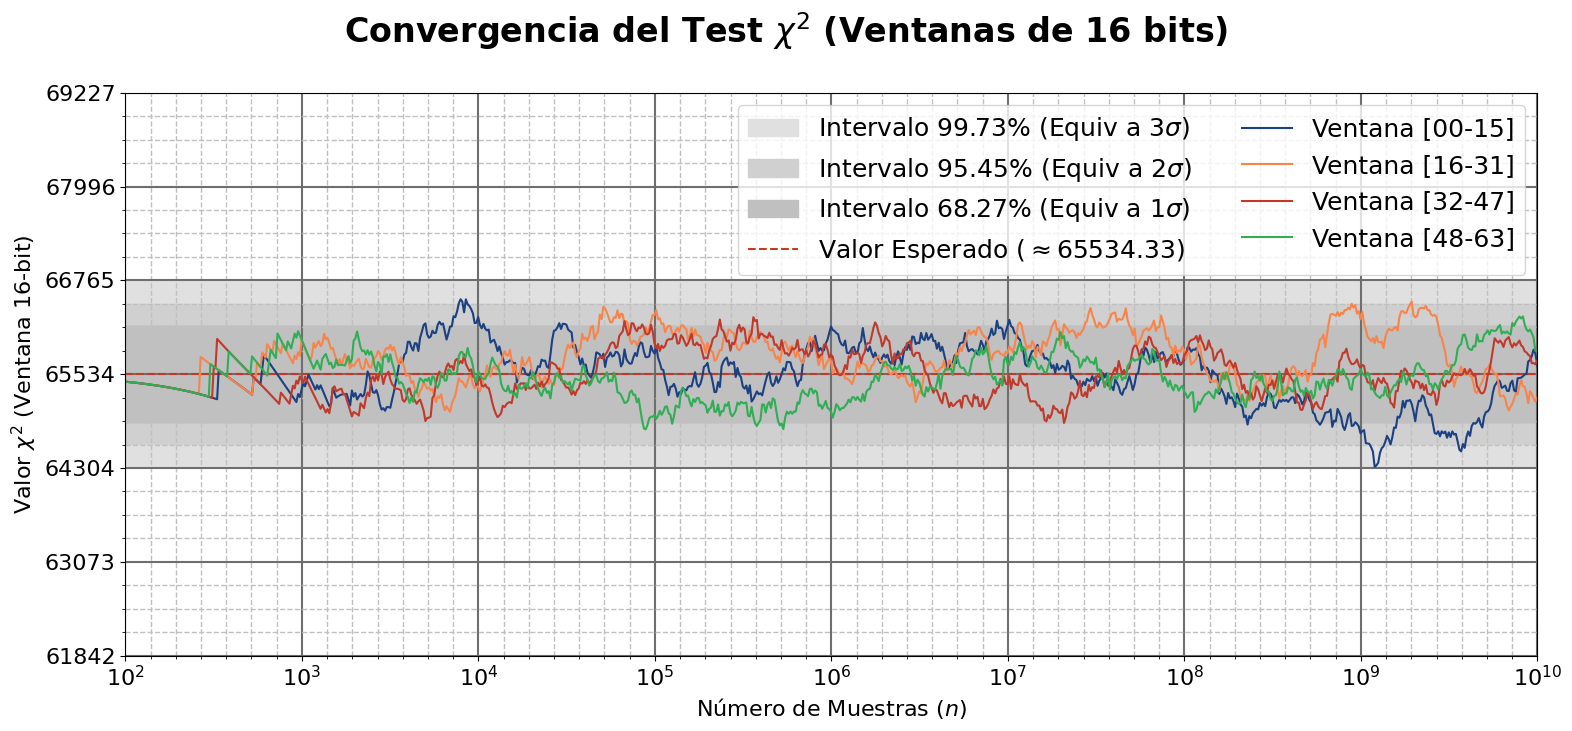

In [ ]:
n_points = [x for x, _ in chi2_log]
chi2_values = np.array([vals for _, vals in chi2_log])

degrees_of_freedom = 2**16 - 1

thresholds = [
    (0.0027, GRAY_LIGHTER, '99.73% (Equiv a 3$\\sigma$)'),
    (0.0455, GRAY_LIGHT,   '95.45% (Equiv a 2$\\sigma$)'),
    (0.3173, GRAY,         '68.27% (Equiv a 1$\\sigma$)'),
]

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xscale('log', base=10)
ax.set_xlim(n_points[0], n_points[-1])

# Escala Y: el intervalo 3σ (con Bonferroni) ocupa el tercio central
y_avg = chi2.ppf(0.5, degrees_of_freedom)
p_low_3s = thresholds[0][0] / 8
val_low_3s = chi2.ppf(p_low_3s, degrees_of_freedom)
val_high_3s = chi2.ppf(1 - p_low_3s, degrees_of_freedom)

margin_3s = (val_high_3s - val_low_3s) / 2.0
y_limit = margin_3s * 3.0

y_min = y_avg - y_limit
y_max = y_avg + y_limit

ax.set_ylim(y_min, y_max)
ax.set_xlabel('Número de Muestras ($n$)')
ax.set_ylabel('Valor $\\chi^2$ (Ventana 16-bit)')

# 2. Ticks
min_pow = int(np.floor(np.log10(n_points[0])))
max_pow = int(np.ceil(np.log10(n_points[-1])))
pow_range = range(min_pow, max_pow + 1)

ax.set_xticks([10**i for i in pow_range])
ax.set_xticklabels([fr'$10^{{{i}}}$' for i in pow_range])

ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.FixedLocator([10**(min_pow + i/7) for i in range((max_pow - min_pow) * 7)]))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

yticks = np.linspace(y_min, y_max, 7)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.0f}' for y in yticks])

# 3. Rejilla
ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

# 4. Títulos
fig.suptitle('Convergencia del Test $\\chi^2$ (Ventanas de 16 bits)', fontweight='bold')

# 5. Elementos principales
for alpha, color, label in thresholds:
    p_low = alpha / 8
    val_low = chi2.ppf(p_low, degrees_of_freedom)
    val_high = chi2.ppf(1 - p_low, degrees_of_freedom)
    ax.fill_between(n_points, val_low, val_high, color=color, label=f'Intervalo {label}')

ax.axhline(y_avg, color=COLOR_RED, linestyle='--', linewidth=1.5,
           label=f'Valor Esperado ($\\approx${y_avg:.2f})')

window_labels = ['Ventana [00-15]', 'Ventana [16-31]', 'Ventana [32-47]', 'Ventana [48-63]']

colors = [COLOR_BLUE, COLOR_ORANGE, COLOR_RED, COLOR_GREEN]
for i in range(4):
    ax.plot(n_points, chi2_values[:, i], label=window_labels[i], color=colors[i], linewidth=1.5)

ax.legend(loc='upper right', ncol=2)

plt.tight_layout()
plt.show()

#### 1.3.2 Convergencia de la Entropía de Shannon ($H$)

Evolución de la Entropía $H$ vs muestras $N$. Referencia teórica $H_{max} = 16.0$ bits.

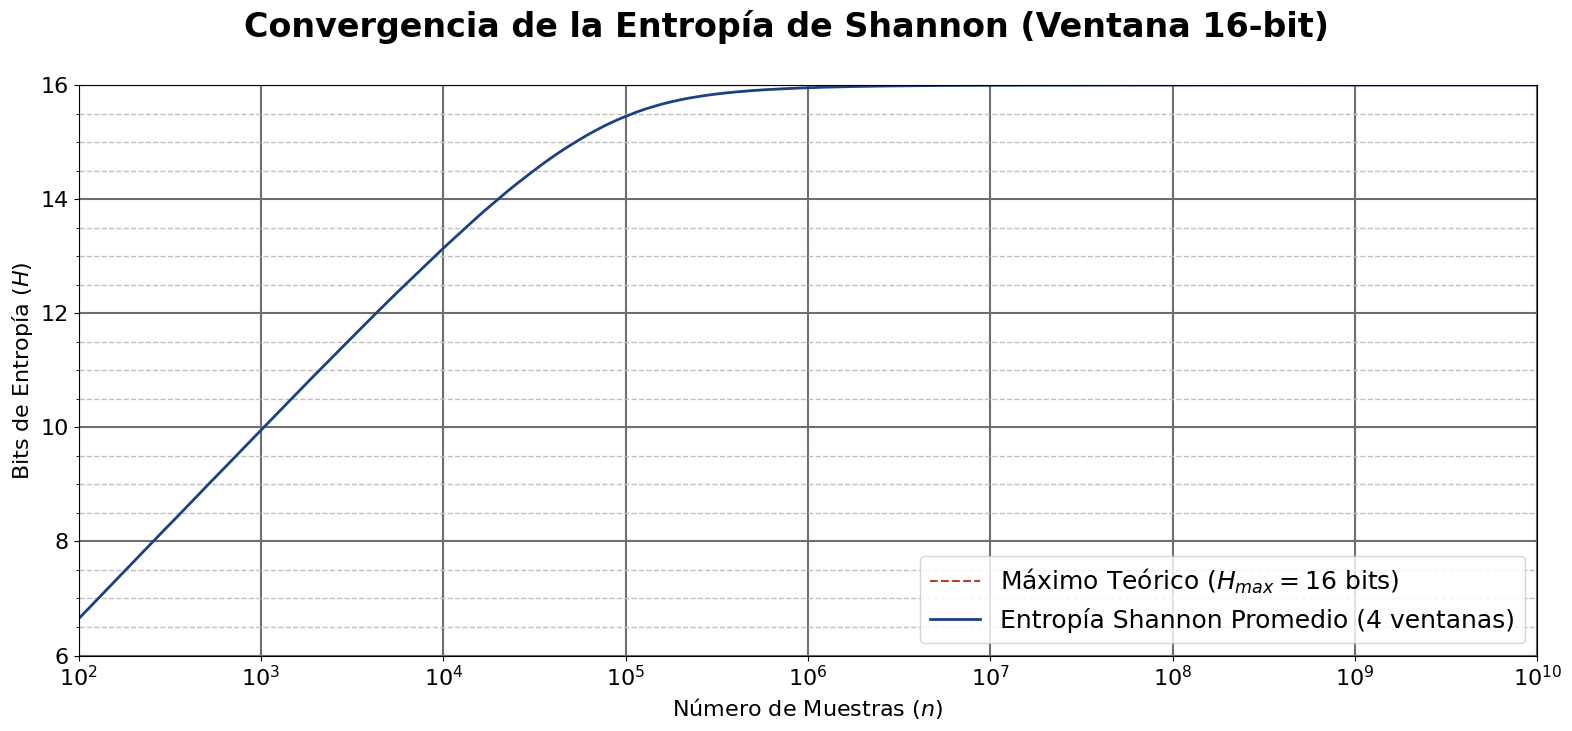

In [ ]:
n_points  = [x for x, _ in chi2_log]
H_shannon = [y for _, y in entropy_log]

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xscale('log', base=LOG_FACTOR)
ax.set_xlim(n_points[0], n_points[-1])

ax.set_ylim(6, 16)

ax.set_xlabel('Número de Muestras ($n$)')
ax.set_ylabel('Bits de Entropía ($H$)')

# 2. Ticks
min_pow = int(np.floor(np.log10(n_points[0])))
max_pow = int(np.ceil(np.log10(n_points[-1])))
pow_range = range(min_pow, max_pow + 1)

ax.set_xticks([10**i for i in pow_range])
ax.set_xticklabels([fr'$10^{{{i}}}$' for i in pow_range])

ax.minorticks_on()
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# 3. Rejilla
ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

# 4. Títulos
fig.suptitle('Convergencia de la Entropía de Shannon (Ventana 16-bit)', fontweight='bold')

# 5. Elementos principales
ax.axhline(16.0, color=COLOR_RED, linestyle='--', linewidth=1.5,
           label='Máximo Teórico ($H_{max} = 16$ bits)')
ax.plot(n_points, H_shannon, label='Entropía Shannon Promedio (4 ventanas)',
        color=COLOR_BLUE, linewidth=2)

ax.legend(loc='lower right')

plt.tight_layout()
plt.show()

#### 1.3.3 Distribución de Frecuencias y Desviaciones ($\delta_{rel}$)

Desviación relativa porcentual por valor de salida (0-255).

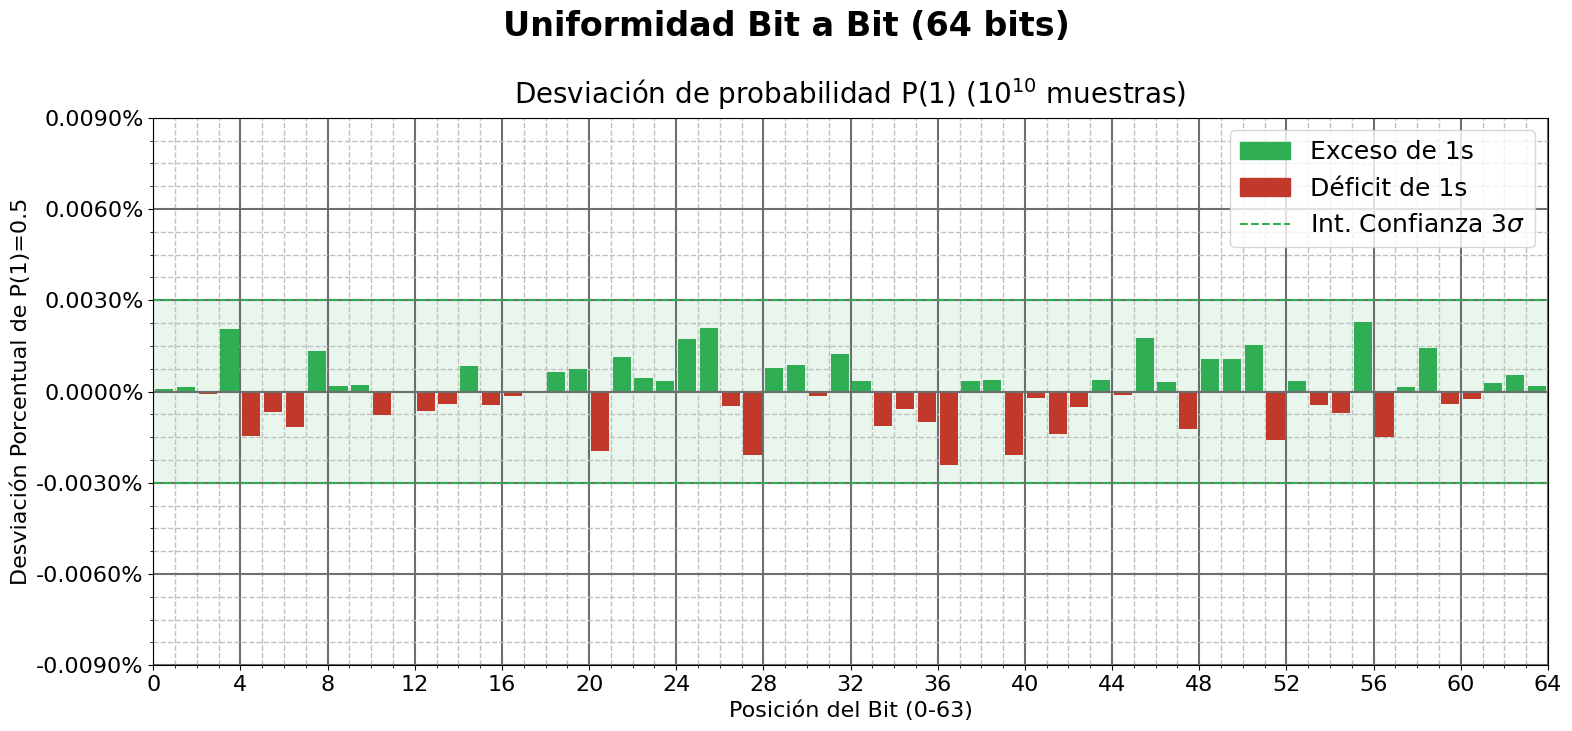

In [ ]:
N = chi2_log[-1][0]
f_exp = N / 2.0
delta_rel = [(f - f_exp) / f_exp * 100 for f in f_abs]

bar_centers = [i + 0.5 for i in range(len(f_abs))]
sigma_3_pct = 300.0 / np.sqrt(N)
y_limit = 3 * sigma_3_pct

fig, ax = plt.subplots(figsize=FIGSIZE)

# 1. Ejes
ax.set_xlim(0, 64)
ax.set_ylim(-y_limit, y_limit)
ax.set_xlabel('Posición del Bit (0-63)')
ax.set_ylabel('Desviación Porcentual de P(1)=0.5')

# 2. Ticks
ax.set_xticks(range(0, 65, 4))
ax.set_xticklabels([f'{x}' for x in range(0, 65, 4)])

yticks = np.linspace(-y_limit, y_limit, 7)
ax.set_yticks(yticks)
ax.set_yticklabels([f'{y:.4f}%' for y in yticks])

ax.minorticks_on()
ax.xaxis.set_minor_locator(plt.MultipleLocator(1))
ax.xaxis.set_minor_formatter(plt.NullFormatter())

# 3. Rejilla
ax.grid(which='major', axis='both', linestyle='-', color=GRAY_DARK, linewidth=1.5)
ax.grid(which='minor', axis='both', linestyle='--', color=GRAY, linewidth=1)

# 4. Títulos
fig.suptitle('Uniformidad Bit a Bit (64 bits)', fontweight='bold')
ax.set_title(f'Desviación de probabilidad P(1) (${10}^{{{np.log10(N):.0f}}}$ muestras)',
             fontsize=SUBTITLE_FONT_SIZE, pad=10)

# 5. Elementos principales
bar_colors = [COLOR_GREEN if d > 0 else COLOR_RED for d in delta_rel]
ax.bar(bar_centers, delta_rel, color=bar_colors, width=5/6, zorder=2)
ax.axhline(y=0, color=GRAY_DARK, linestyle='-', linewidth=1.5)

ax.axhline(y=sigma_3_pct, color=COLOR_GREEN, linestyle='--', linewidth=1.5)
ax.axhline(y=-sigma_3_pct, color=COLOR_GREEN, linestyle='--', linewidth=1.5)
ax.fill_between([-1, 64], -sigma_3_pct, sigma_3_pct, color=COLOR_GREEN, alpha=0.1)

positive_patch = mpatches.Patch(color=COLOR_GREEN, label='Exceso de 1s')
negative_patch = mpatches.Patch(color=COLOR_RED, label='Déficit de 1s')
confidence_line = plt.Line2D([0], [0], color=COLOR_GREEN, linestyle='--',
                             label='Int. Confianza 3$\\sigma$')
ax.legend(handles=[positive_patch, negative_patch, confidence_line], loc='upper right')

plt.tight_layout()
plt.show()

## 2. Test de Avalancha

Análisis Sensibilidad de entrada/salida (Efecto Avalancha). Objetivo: cambio de ~50% bits salida ante cambio de 1 bit entrada.

### 2.1 Extracción de Datos


Generación de métricas de avalancha: cambios en salida vs flips de 1 bit en $S, X, Y$.

In [ ]:
AVALANCHE_SAMPLES = 100_000_000
AVALANCHE_SEED = 123456789

avalanche_output_file = Path("results/avalanche_64b_output.txt")
avalanche_output_file.parent.mkdir(parents=True, exist_ok=True)

print("Compilando avalanche_test...")
subprocess.run(["make", "compile_avalanche_64b"], check=True)

cmd = ["./bin/avalanche_64b", str(AVALANCHE_SAMPLES), str(AVALANCHE_SEED)]
print(" ".join(cmd))

result = subprocess.run(cmd, capture_output=True, text=True, check=True)
data_avalanche = result.stdout
avalanche_output_file.write_text(data_avalanche)

Compilando avalanche_test...
mkdir -p ./bin
gcc -fopenmp -Wall -std=c23 -march=native -mbmi2 -Ofast -o ./bin/avalanche_64b common.c tests/test_avalanche_64b.c -lm -lpng
./bin/avalanche_64b 100000000 123456789


117231

#### 2.1.1 Datos en bruto obtenidos

In [ ]:
data_avalanche.strip().splitlines()[:16]

['000, 000000000000, 000000000000, 000000000000',
 '001, 000000000000, 000000000000, 000000000000',
 '002, 000000000000, 000000000000, 000000000000',
 '003, 000000000000, 000000000000, 000000000000',
 '004, 000000000000, 000000000000, 000000000000',
 '005, 000000000000, 000000000000, 000000000000',
 '006, 000000000000, 000000000000, 000000000000',
 '007, 000000000000, 000000000000, 000000000002',
 '008, 000000000003, 000000000002, 000000000000',
 '009, 000000000008, 000000000015, 000000000015',
 '010, 000000000056, 000000000060, 000000000061',
 '011, 000000000296, 000000000287, 000000000286',
 '012, 000000001251, 000000001235, 000000001202',
 '013, 000000005165, 000000004880, 000000004800',
 '014, 000000017812, 000000017569, 000000017494',
 '015, 000000058647, 000000058151, 000000057926']

In [ ]:
data_avalanche.strip().splitlines()[66:70]

['000: 003199981429, 003200025619, 003199957845 | S[50005196,50004145,49997179,50001130,50000825,49998337,49996630,50002604,49995650,50001181,49987544,49996421,49995521,49994417,49994290,50006064,50007396,49999835,49995766,49999544,50003073,50003535,49994091,49990286,49996250,49998493,49996213,50001523,50000712,49998352,49996805,50003894,50001031,49989581,49994007,49999975,49999705,49999058,49996897,49998419,49993500,50004136,50000334,50000662,50005889,50003741,49994030,50011390,50005138,50009281,50006257,50010151,49997596,49997934,50003668,49999953,50004140,49997539,49997785,49992572,50006516,50002098,49998999,49996545] X[50006720,49994733,49999337,50000628,49992644,50004502,50007300,50000949,50004358,49990188,50005167,49992180,50003885,50007003,49999378,50006455,49987457,50002245,50001758,50001233,49991770,49999848,50007506,49999906,50006345,50005684,49993005,49999311,49996444,50000365,49995463,50010376,49997819,49992135,49995774,50001708,49988697,50010051,50002839,49999870,50000607,

### 2.2 Refinado de Datos

Procesamiento: Frecuencias Hamming ($f_h$) y media cambios/bit ($\mu$).

In [ ]:
dist_regex = re.compile(r'(\d+),\s+(\d+),\s+(\d+),\s+(\d+)')
dist_data = dist_regex.findall(data_avalanche)

sac_regex = re.compile(r'(\d+):\s+(\d+),\s+(\d+),\s+(\d+)\s+\|\s+S\[(.*?)\]\s+X\[(.*?)\]\s+Y\[(.*?)\]')
sac_matches = sac_regex.findall(data_avalanche)

f_h_s = [int(r[1]) for r in dist_data]
f_h_x = [int(r[2]) for r in dist_data]
f_h_y = [int(r[3]) for r in dist_data]
f_h_total = [s + x + y for s, x, y in zip(f_h_s, f_h_x, f_h_y)]

mu_flips_s = [int(r[1]) / AVALANCHE_SAMPLES for r in sac_matches]
mu_flips_x = [int(r[2]) / AVALANCHE_SAMPLES for r in sac_matches]
mu_flips_y = [int(r[3]) / AVALANCHE_SAMPLES for r in sac_matches]

# Matrices SAC (64x64): P(flip) por cada par (bit_entrada, bit_salida)
sac_matrix_s = np.array([list(map(int, r[4].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES
sac_matrix_x = np.array([list(map(int, r[5].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES
sac_matrix_y = np.array([list(map(int, r[6].split(','))) for r in sac_matches]) / AVALANCHE_SAMPLES

### 2.3 Visualización de Datos

#### 2.3.1 Análisis de la Distribución de Hamming y Efecto Avalancha

Comparación métricas observadas vs ideal teórico (Binomial, $\mu=32.0$).

In [ ]:
mu_global = np.mean([mu_flips_s, mu_flips_x, mu_flips_y])

print(f"Promedio global de bits de salida girados ($\\mu$): {mu_global:.8f} (Ideal: 32.0)")
print(f"\tDesviación respecto al ideal: {abs(32.0 - mu_global):.8f}")
print("-" * 50)
print(f"Media S ($\\mu_s$): {np.mean(mu_flips_s):.8f}")
print(f"Media X ($\\mu_x$): {np.mean(mu_flips_x):.8f}")
print(f"Media Y ($\\mu_y$): {np.mean(mu_flips_y):.8f}")

Promedio global de bits de salida girados ($\mu$): 32.00002120 (Ideal: 32.0)
	Desviación respecto al ideal: 0.00002120
--------------------------------------------------
Media S ($\mu_s$): 32.00002611
Media X ($\mu_x$): 32.00000732
Media Y ($\mu_y$): 32.00003017


In [ ]:
def plot_avalanche_effect(data, title):
    std_err = np.sqrt(64 * 0.5 * 0.5 / AVALANCHE_SAMPLES)
    margin = 3.0 * std_err
    ci_lower, ci_upper = 32.0 - margin, 32.0 + margin

    fig, ax = plt.subplots(figsize=FIGSIZE)

    # 1. Ejes
    ax.set_xlim(0, 64)
    y_min = 32.0 - margin * 3
    y_max = 32.0 + margin * 3
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Posición del bit de entrada $j$ (0-63)')
    ax.set_ylabel('$\\mu$ bits girados')

    # 2. Ticks
    ax.set_xticks(np.arange(0, 65, 4))

    yticks = np.linspace(y_min, y_max, 7)
    ax.set_yticks(yticks)
    ax.set_yticklabels([f'{y:.5f}' for y in yticks])

    ax.minorticks_on()
    ax.xaxis.set_minor_locator(plt.MultipleLocator(1))

    # 3. Rejilla
    ax.grid(which='major', linestyle='-', linewidth=1.5, color=GRAY_DARK)
    ax.grid(which='minor', linestyle='--', linewidth=1, color=GRAY)

    # 4. Títulos
    fig.suptitle(title, fontweight='bold')
    ax.set_title(f'Intervalo de confianza $3\\sigma \\approx 99.73\\%$ ($N=10^{{{int(np.log10(AVALANCHE_SAMPLES))}}}$)',
                 fontsize=SUBTITLE_FONT_SIZE, pad=10)

    # 5. Elementos principales
    ax.fill_between(range(65), ci_lower, ci_upper, color=COLOR_GREEN, alpha=0.2,
                    label='Zona de Aceptación (3$\\sigma$)')
    ax.axhline(y=32.0, color=COLOR_RED, linestyle='--', linewidth=1.5,
               label='Media Teórica ($\\mu=32.0$)')
    ax.stairs(list(data) + [data[-1]], baseline=None, color=COLOR_BLUE, linewidth=2,
                  zorder=2, label='Media Observada ($\\mu$)', alpha=0.8)

    ax.legend(loc='upper right')

    plt.tight_layout()
    plt.show()

#### 2.3.2 Efecto Avalancha: Variando bits de $Seed$

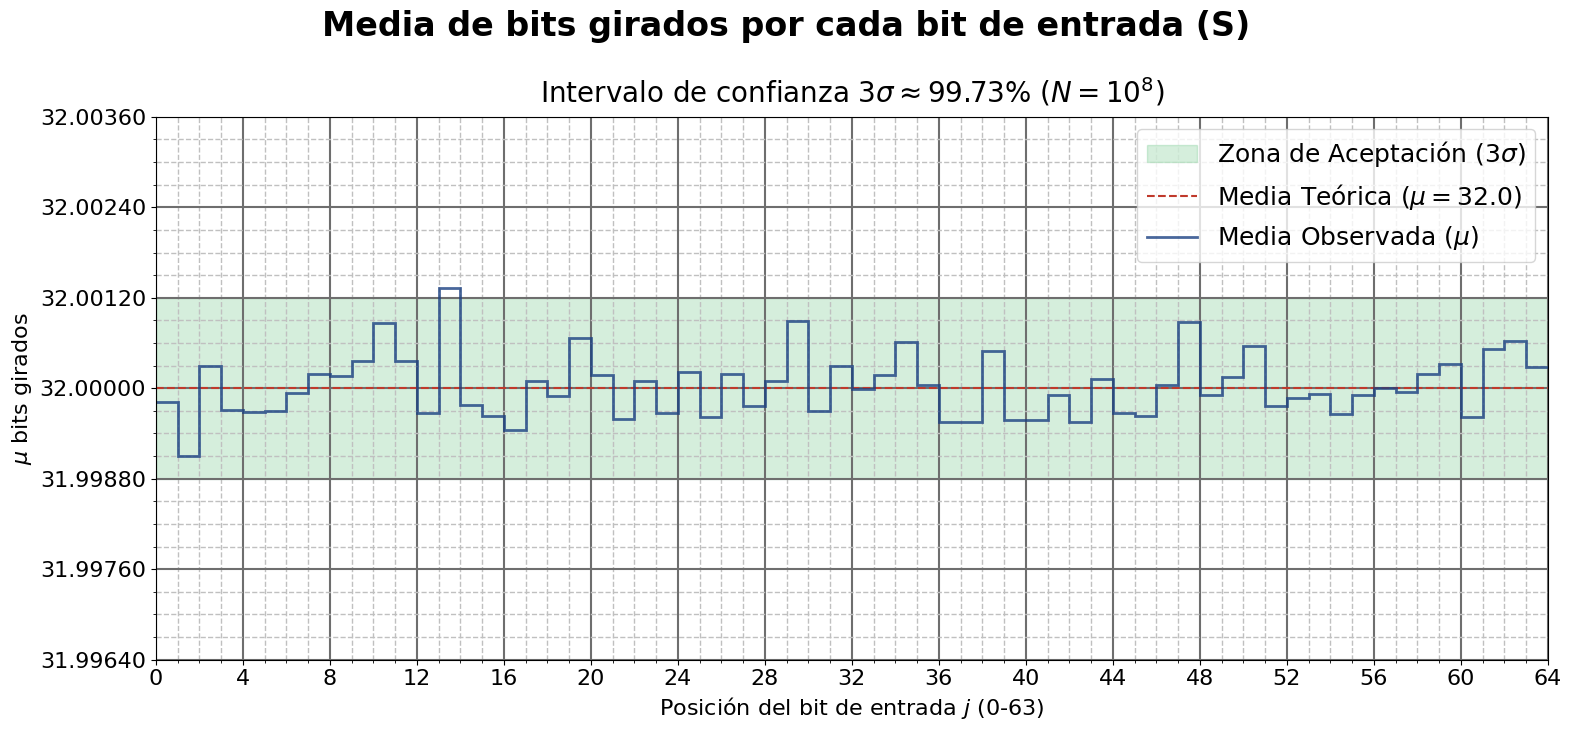

In [ ]:
plot_avalanche_effect(mu_flips_s, "Media de bits girados por cada bit de entrada (S)")

#### 2.3.3 Efecto Avalancha: Variando bits de $X$


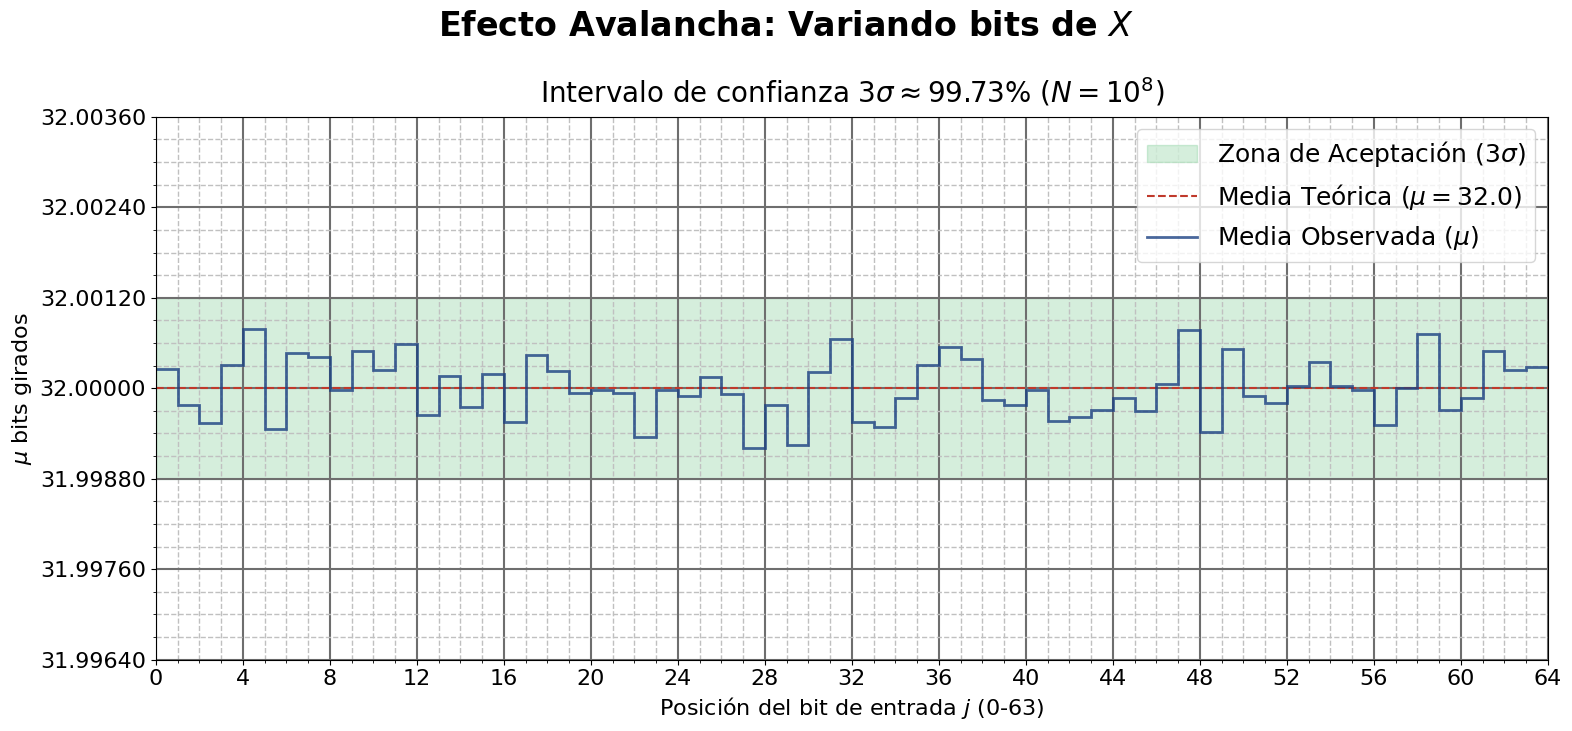

In [ ]:
plot_avalanche_effect(mu_flips_x, 'Efecto Avalancha: Variando bits de $X$')

#### 2.3.4 Efecto Avalancha: Variando bits de $Y$

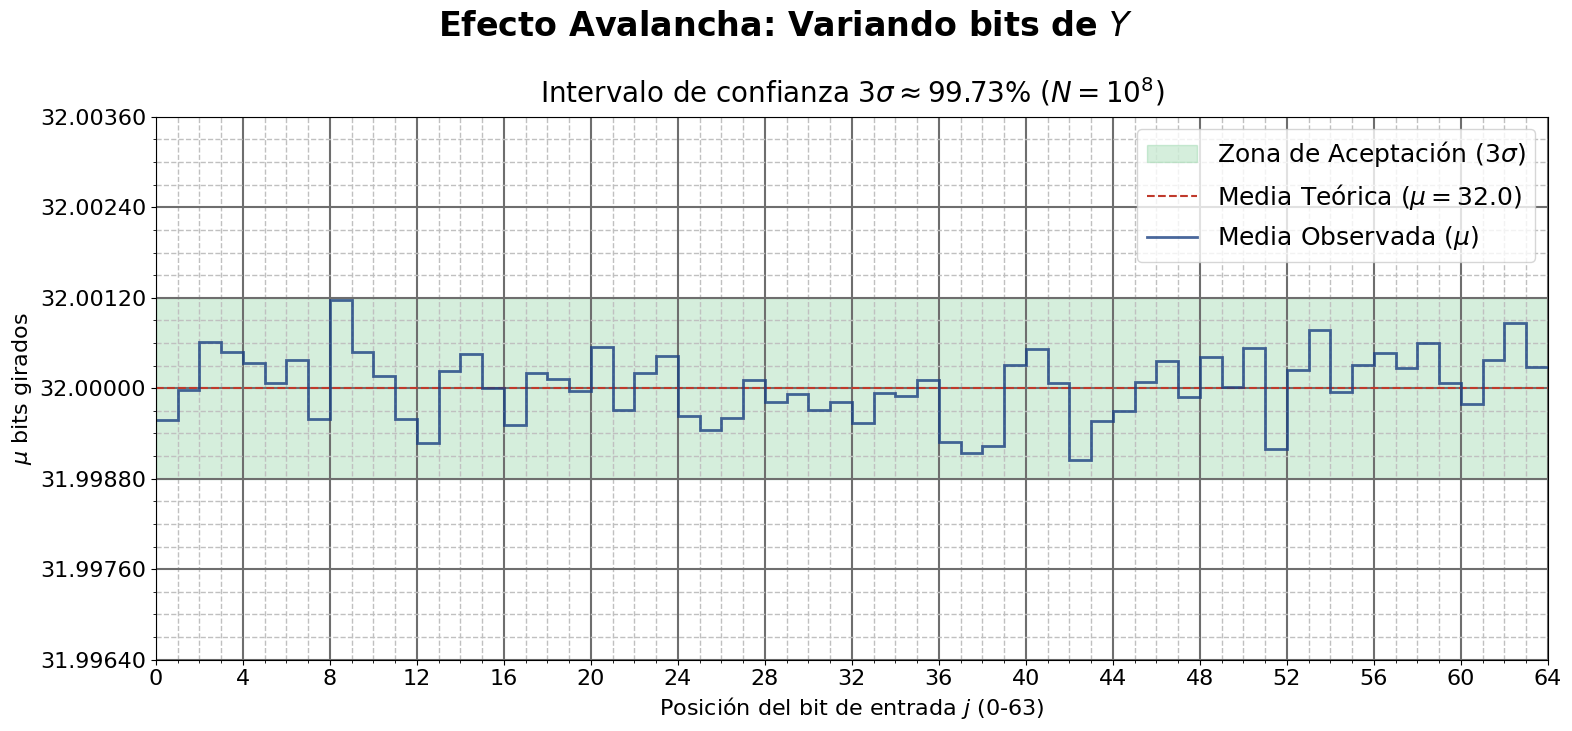

In [ ]:
plot_avalanche_effect(mu_flips_y, 'Efecto Avalancha: Variando bits de $Y$')

#### 2.3.5 Distribución de Bits Cambiados (Distancia de Hamming $h$)

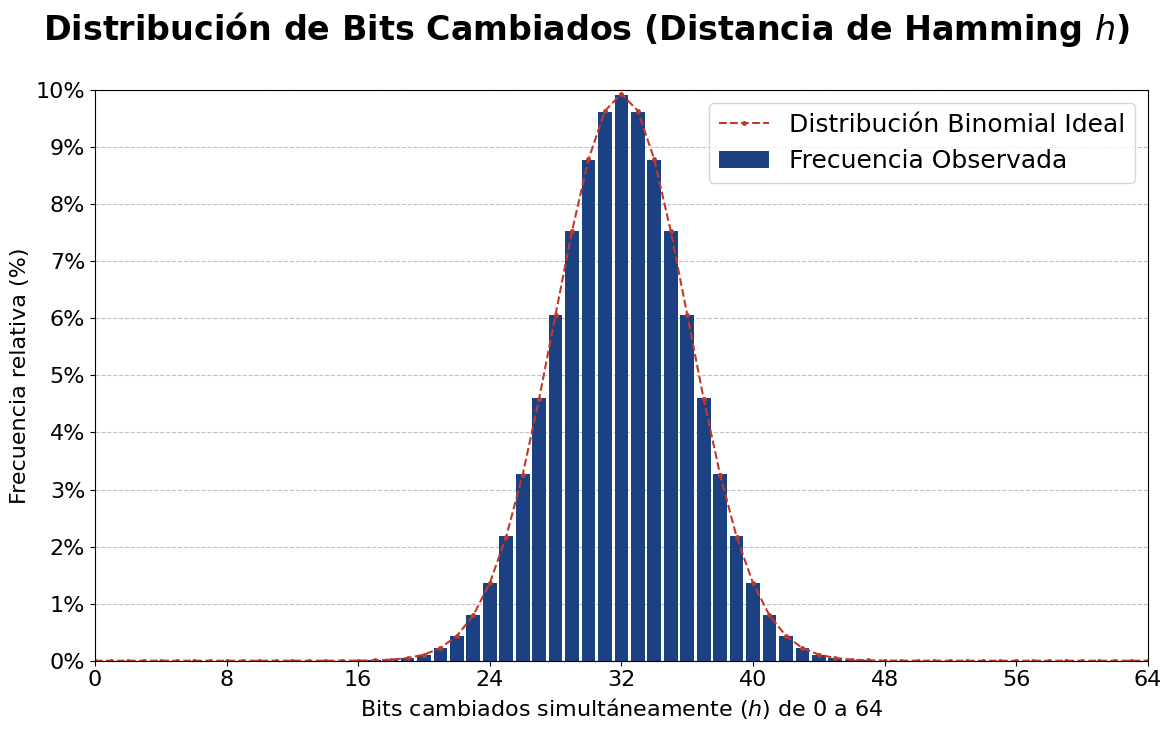

In [ ]:
fig, ax = plt.subplots(figsize=(12, 7.5))

# 1. Ejes
h_vals = np.arange(len(f_h_total))
ax.set_xlabel('Bits cambiados simultáneamente ($h$) de 0 a 64')
ax.set_ylabel('Frecuencia relativa (%)')
ax.set_xlim(0, 64)
ax.set_ylim(0, 0.1)

# 2. Ticks
ax.set_xticks(range(0, 65, 8))
yticks_vals = np.linspace(0, 0.1, 11)
ax.set_yticks(yticks_vals)
ax.set_yticklabels([f'{y * 100:.0f}%' for y in yticks_vals])

# 3. Rejilla
ax.grid(axis='y', linestyle='--', color=GRAY)

# 4. Títulos
fig.suptitle('Distribución de Bits Cambiados (Distancia de Hamming $h$)', fontweight='bold')

# 5. Elementos principales
total_ensayos = 3 * 64 * AVALANCHE_SAMPLES
f_rel_total = np.array(f_h_total) / total_ensayos
dist_binomial = binom.pmf(h_vals, 64, 0.5)

ax.bar(h_vals, f_rel_total, width=5/6, color=COLOR_BLUE, label='Frecuencia Observada', zorder=2)
ax.plot(h_vals, dist_binomial, color=COLOR_RED, linestyle='--', marker='.',
        markersize=5, label='Distribución Binomial Ideal')

ax.legend()
plt.tight_layout()
plt.show()

#### 2.3.6 Análisis del Criterio de Avalancha Estricto (SAC)

Evaluación detallada de la independencia de bits.
*   **Izquierda:** Matriz $(i, j)$ donde varía S.
*   **Centro:** Matriz $(i, j)$ donde varía X.
*   **Derecha:** Matriz $(i, j)$ donde varía Y.

Cada celda representa la probabilidad de cambio en el bit de salida $j$ al invertir el bit de entrada $i$. El valor ideal es $0.5$ (verde). Desviaciones significativas (rojo) indican correlaciones no deseadas.

#### 2.3.7 Análisis Integral del SAC (S, X, Y)


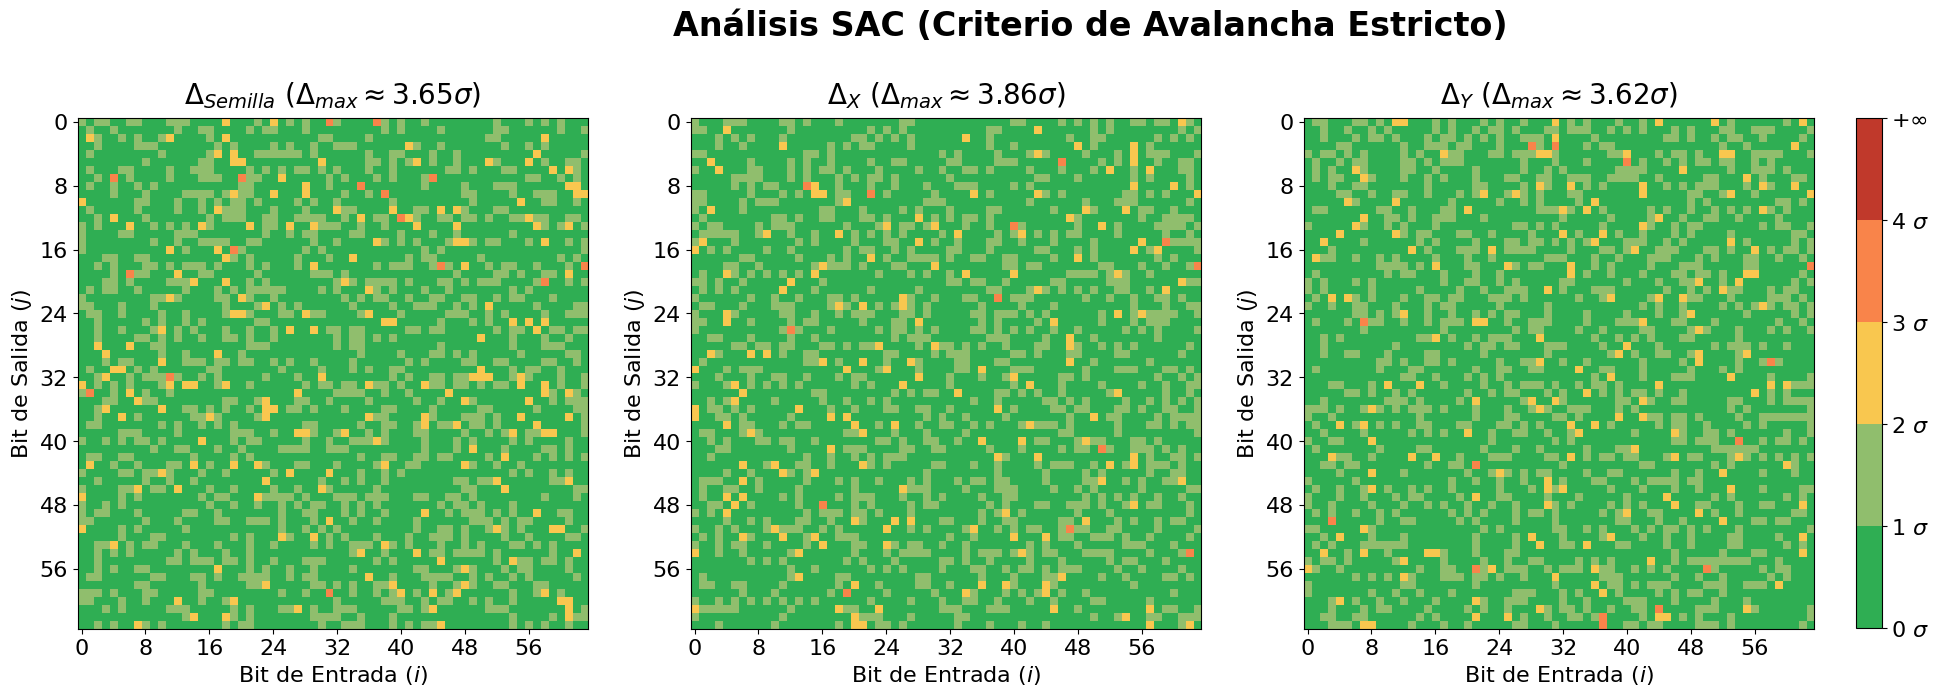

In [ ]:
sac_configs = [
    (sac_matrix_s, '$\\Delta_{{Semilla}}$'),
    (sac_matrix_x, '$\\Delta_{{X}}$'),
    (sac_matrix_y, '$\\Delta_{{Y}}$')
]

fig, axes = plt.subplots(1, len(sac_configs), figsize=(27, 7.5))
axes = axes.flatten()

std_err_bit = 0.5 / np.sqrt(AVALANCHE_SAMPLES)
cmap = ListedColormap([COLOR_GREEN, COLOR_LIGHT_GREEN, COLOR_YELLOW, COLOR_ORANGE, COLOR_RED])

for i, (matrix, title) in enumerate(sac_configs):
    ax = axes[i]
    z_scores = np.abs(matrix.T - 0.5) / std_err_bit
    z_mapped = np.digitize(z_scores, [1, 2, 3, 4, 100])
    dev_max_sigma = np.max(z_scores)

    # 1. Ejes
    ax.set_xlim(-0.5, 63.5)
    ax.set_ylim(63.5, -0.5)
    ax.set_xlabel('Bit de Entrada ($i$)')
    ax.set_ylabel('Bit de Salida ($j$)')

    # 2. Ticks
    ax.set_xticks(np.arange(0, 64, 8))
    ax.set_yticks(np.arange(0, 64, 8))

    # 3. Títulos
    ax.set_title(f"{title} ($\\Delta_{{max}} \\approx {dev_max_sigma:.2f}\\sigma$)",
                 fontsize=SUBTITLE_FONT_SIZE, pad=10)

    # 4. Elementos principales
    im = ax.imshow(z_mapped, cmap=cmap, vmin=0, vmax=5, aspect='equal', zorder=2)

# 5. Título y leyenda global
fig.suptitle('Análisis SAC (Criterio de Avalancha Estricto)', fontweight='bold')

cbar = fig.colorbar(im, ax=axes.tolist(), pad=0.02, shrink=883/1000)
cbar.set_ticks([0, 1, 2, 3, 4, 5])
cbar.set_ticklabels(['0 $\\sigma$', '1 $\\sigma$', '2 $\\sigma$', '3 $\\sigma$', '4 $\\sigma$', '$+\\infty$'])

plt.show()

## 3. Test de Patrones

Evaluación dual para detectar repeticiones no deseadas:
1. **Dominio Espacial:** Inspección visual directa para identificar artefactos geométricos.
2. **Dominio de Frecuencia (FFT):** Verificación matemática de la ausencia de periodicidad oculta.

### 3.1 Extracción de Datos

Generación de imágenes de secciones 2D (Planos XY, XS, SY).

In [ ]:
print("Compilando pattern_test...")
subprocess.run(["make", "compile_pattern_64b"], check=True)

PATTERN_S = 0
PATTERN_X = 0
PATTERN_Y = 0
PATTERN_SIZE = 256
PATTERN_OUT_DIR = Path("./results")
PATTERN_OUT_DIR.mkdir(parents=True, exist_ok=True)

print("\nEjecutando test...")
cmd = ["./bin/pattern_64b", str(PATTERN_S), str(PATTERN_X), str(PATTERN_Y), str(PATTERN_SIZE), str(PATTERN_OUT_DIR)]

subprocess.run(cmd, check=True)
print(' '.join(cmd))

Compilando pattern_test...
mkdir -p ./bin
gcc -fopenmp -Wall -std=c23 -march=native -mbmi2 -flto -Ofast -o ./bin/pattern_64b common.c tests/test_pattern_64b.c -lm -lpng

Ejecutando test...
./bin/pattern_64b 0 0 0 256 results


In [ ]:
def plot_matrix_comparison(data_list, subplot_titles, main_title, axes_labels, cbar_label=None):
    fig, axes = plt.subplots(1, 3, figsize=(24, 6))

    for i, data in enumerate(data_list):
        ax = axes[i]

        # 1. Ejes
        ax.set_xlabel(axes_labels[i][0])
        ax.set_ylabel(axes_labels[i][1])

        # 2. Ticks
        size = data.shape[0]
        ticks = np.linspace(0, size, 9)
        ax.set_xticks(ticks)
        ax.set_yticks(ticks)
        ax.set_xticklabels([f'{int(t)}' for t in ticks])
        ax.set_yticklabels([f'{int(t)}' for t in ticks])

        # 3. Títulos
        ax.set_title(subplot_titles[i], fontsize=SUBTITLE_FONT_SIZE)

        # 4. Elementos principales
        im = ax.imshow(data, cmap='gray', origin='lower')

    # 5. Título y leyenda global
    fig.suptitle(main_title, fontweight='bold')
    fig.colorbar(im, ax=axes.tolist(), shrink=0.950, aspect=10, pad=0.04, label=cbar_label)

    plt.show()

### 3.2 Inspección Visual (Dominio Espacial)

Visualización directa de los cortes generados (Salida PNG via libpng).

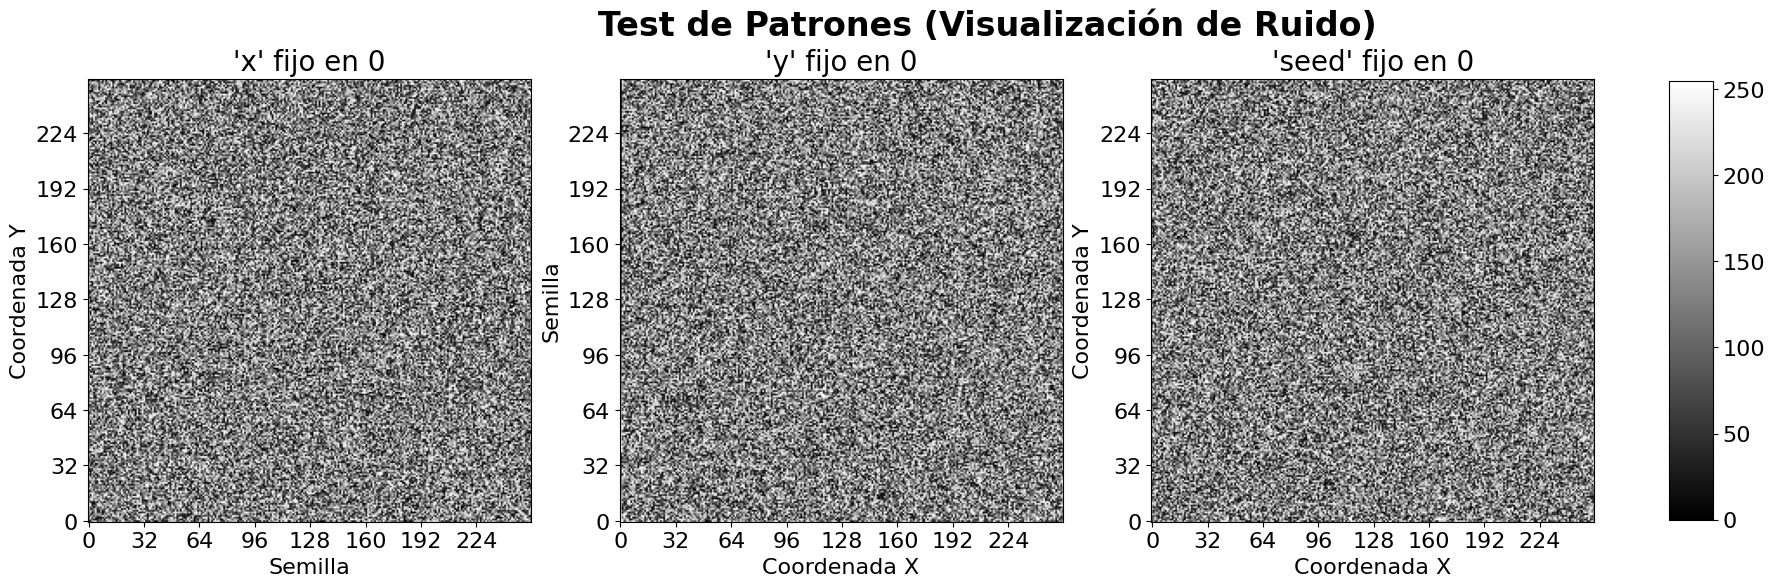

In [ ]:
configs = [
    ('x', PATTERN_X, 'pattern_sy.png', "Semilla", "Coordenada Y"),
    ('y', PATTERN_Y, 'pattern_xs.png', "Coordenada X", "Semilla"),
    ('seed', PATTERN_S, 'pattern_xy.png', "Coordenada X", "Coordenada Y")
]

pattern_data_list = [np.array(Image.open(PATTERN_OUT_DIR / c[2])) for c in configs]
subplot_titles    = [f"'{c[0]}' fijo en {c[1]}" for c in configs]
spatial_labels    = [(c[3], c[4]) for c in configs]

plot_matrix_comparison(pattern_data_list, subplot_titles,
                       "Test de Patrones (Visualización de Ruido)",
                       spatial_labels)

### 3.3 Análisis Espectral (FFT)

Transformada de Fourier 2D para analizar el dominio de la frecuencia.

**Objetivo:** Verificar la ausencia de periodicidad. Un buen ruido aleatorio (ruido blanco) debe mostrar una distribución de energía uniforme (espectro plano) sin picos dominantes o patrones geométricos claros (estrellas, líneas fuertes) que revelarían regularidades en el hash.

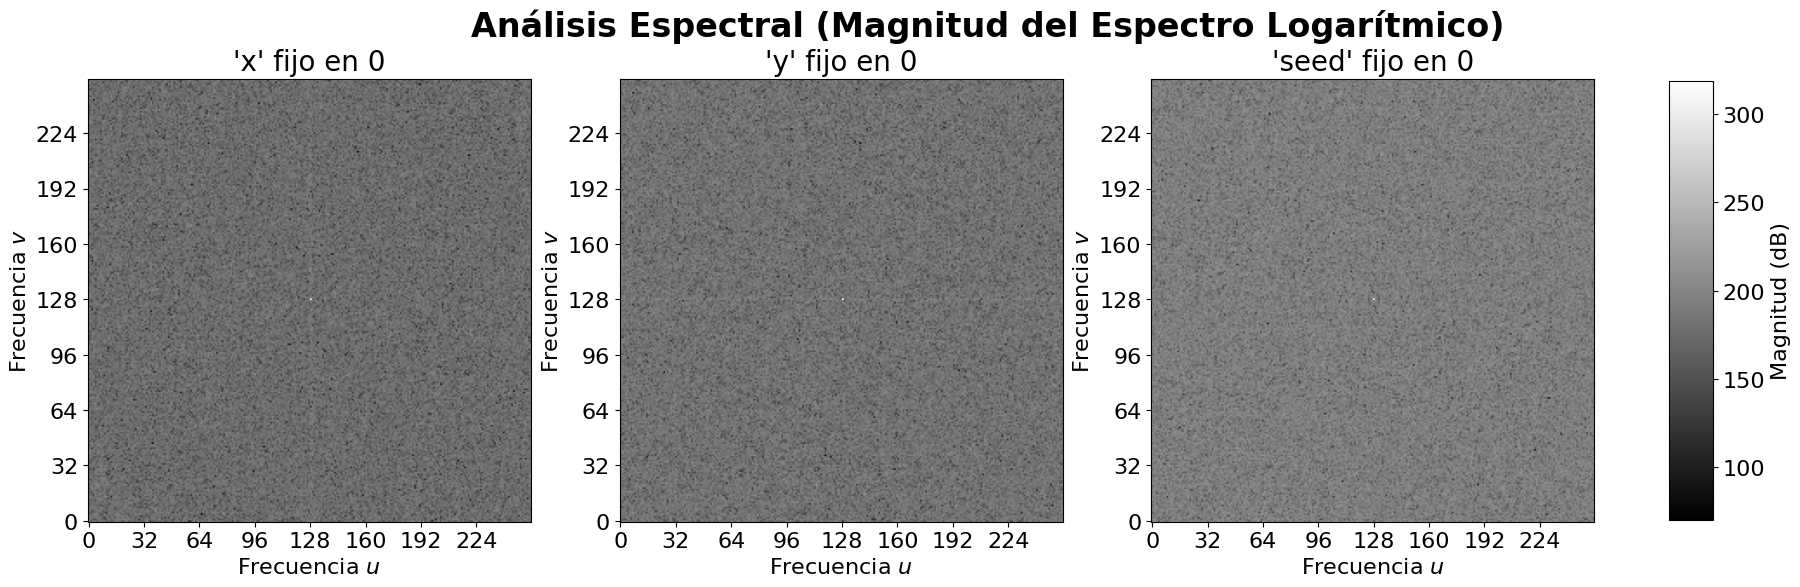

In [ ]:
fft_data_list = []
for data in pattern_data_list:
    f_shift = np.fft.fftshift(np.fft.fft2(data))
    fft_data_list.append(20 * np.log(np.abs(f_shift) + 1e-9))

fft_labels = [("Frecuencia $u$", "Frecuencia $v$")] * 3

plot_matrix_comparison(fft_data_list, subplot_titles,
                       "Análisis Espectral (Magnitud del Espectro Logarítmico)",
                       fft_labels,
                       cbar_label="Magnitud (dB)")